In [11]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.sparse.linalg import cg as sp_cg

import pandas as pd

from trips.test_problems.Tomography import Tomography
import astra

import jlinops

import numpy as np
import math

from jlinops.base import _CustomLinearOperator
# from .util import get_device

# from ias import IASSolver

from trips.utilities.phantoms import shepp_logan

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])

method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "solid",
    "FLSQR-I": "solid",
    "FLSQR-R": "solid",
    "FLSQR-W": "solid",
    "IRW-FLSQR": "solid",
}



from PIL import Image
import numpy as np

CMAP = "gray"

import sys
import os

# Go three directories up
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)



from msolver import MM2019GKS, IASGKS, VanillaGKS, MMGKS
from fsolver import IASFGK, MM2019FGK, MMFGK # VanillaFK
from pgkbsolver import MM2019GKB, IASGKB, MMGKB
from f2019solver import MM2019FGK2019, IASFGK2019

from pinv import CGWeightedNeumann2DPinvOperatorGPU

ModuleNotFoundError: No module named 'pandas'

# Setup problem

In [12]:
np.random.seed(0)
theta_max = np.pi
#Tomo = Tomography (geom="fanflat", CommitCrime=True, theta_max=theta_max)
#Tomo = Tomography (geom="fanflat", CommitCrime=True)
Tomo = Tomography (geom="parallel", CommitCrime=False, theta_max=theta_max)
views = 28
noise_percent = 0.01 # percent of maximum of noiseless signal A x_true
N = 256

x_true = shepp_logan(N)
img_shape = x_true.shape
nx, ny = x_true.shape
(F , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )

noise_stdev = noise_percent*np.amax(b_true)
noise_var = noise_stdev**2
print(f"Noise level: {noise_percent}")
print(f"Noise stdev: {noise_stdev}")
print(f"Noise var: {noise_var}")


b_noisy = b_true.flatten() + noise_stdev*np.random.normal(size=b_true.flatten().shape)
b_noisy_shaped = b_noisy.reshape((p,q))
noisy_signal = b_noisy.flatten()
m, n = F.shape


# Define linear operator implementing A
_matvec_fn = lambda x: F.matvec(x)
_rmatvec_fn = lambda x: F.rmatvec(x)
A = _CustomLinearOperator( (m,n), _matvec_fn, _rmatvec_fn, device="cpu")

# Underdetermined rate:
underdetermined_rate = noisy_signal.size/(nx*ny)
print(f"Underdetermined rate: {underdetermined_rate}")

settings
no crime
Noise level: 0.01
Noise stdev: 0.6781836700439453
Noise var: 0.4599330903142749
Underdetermined rate: 0.1546630859375


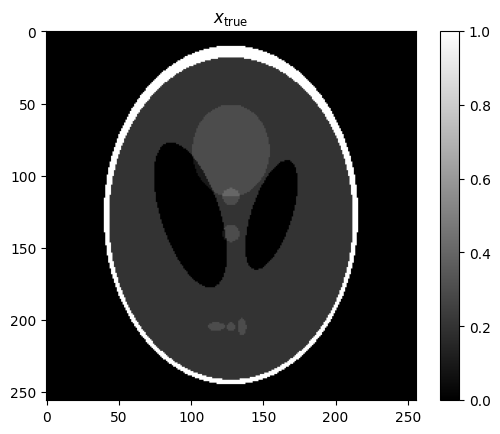

In [13]:
plt.imshow(x_true.reshape((nx,ny)), cmap=CMAP)
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

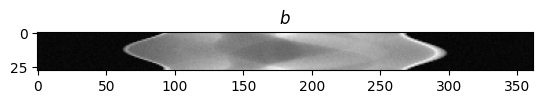

In [14]:
plt.imshow(b_noisy_shaped, cmap=CMAP)
plt.title("$b$")
plt.show()

# Setup prior

In [15]:
# Set method
Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# # Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None

K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)


def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-4, *args, **kwargs)


# mm_weight_params_2019 = {
#     "q": 1.0,
#     "tau1": 1e-10,
#     "tau2": 1e-16,
# }

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-3,
}

ias_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

# Setup solvers

In [16]:
# Build solvers
gks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

mm_gks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm_fgk_solver = MMFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm_gkb_solver = MMGKB(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

ias_gks_solver = IASGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_fgk_solver = IASFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_gkb_solver = IASGKB(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# Misc
AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b_noisy)

# Run all solvers

In [17]:
# Parameters
method = "dp"
n_its = 30
n_its_recres = 100
restart_dim = 15
recycle_dim = 15
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

In [18]:
%%capture 

all_v_results = []

# GKS
v_gks_data = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})

all_v_results.append( ( "V", "GKS", v_gks_data  ) )


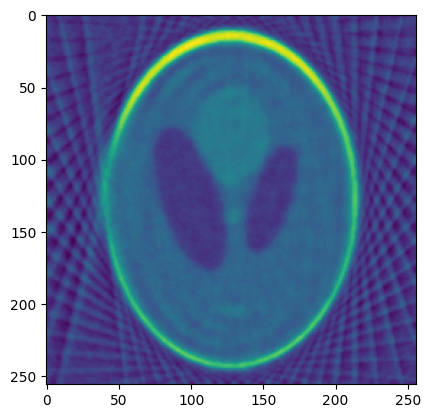

In [19]:
plt.imshow(v_gks_data["x"].reshape(img_shape))

In [20]:
all_mm_results = []

# S-GKS
mm_sgks_data = mm_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "S-GKS", mm_sgks_data  ) )

# Restarted S-GKS
mm_ressgks_data = mm_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

all_mm_results.append( ( "MM", "S-GKS (restarted)", mm_ressgks_data  ) )

# Recycled S-GKS
mm_recsgks_data = mm_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

all_mm_results.append( ( "MM", "S-GKS (recycled)", mm_recsgks_data  ) )


# PS-GKS
mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params,
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS", mm_psgks_data  ) )


# Restarted PS-GKS
mm_respsgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params, restart_dim=restart_dim,
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS (restarted)", mm_psgks_data  ) )


# Recycled PS-GKS
mm_recpsgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params, dim_max=recycle_dim, dim_min=5,
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS (recycled)", mm_recpsgks_data  ) )


# PS-GKB solver
mm_gkb_data = mm_gkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=mm_weight_params,
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )
all_mm_results.append( ( "MM", "PS-GKB", mm_gkb_data  ) )


# FGK solver
mm_fgk_data = mm_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=mm_weight_params, refresh_basis=False, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FGK", mm_fgk_data  ) )



Augmented basis with initial guess!


9.234564556908456
9.042833486720669
9.220460401899409
9.368163374872363
9.764566150885162
10.335295122994635
10.654572524803857
10.776896900846758
10.762266370990794
10.756509221315193
11.058558049060872
11.18303573224031
11.192930076143577
11.15849437534961
11.08291204321627
10.975693084985261
10.89113163821695
10.821582202093587
10.745002749182865
10.6869107732876
10.64296156311083
10.60856597874358
10.579120629892923
10.556117238885397
10.536458185634286
10.520502540650684
10.50565845494671
10.489665316266683
10.480570063157597
10.473574971406457
Augmented basis with initial guess!


9.234564556908456
9.042833486720669
9.220460401899409
9.368163374872363
9.764566150885162
10.335295122994635
10.654572524803857
10.776896900846758
10.762266370990794
10.756509221315193
11.058558049060872
11.18303573224031
11.192930076143577
11.15849437534961
11.08291204321627
10.975693084985261
10.89113163821695
10.821582202093587
10.745002749182865
10.6869107732876
10.64296156311083
10.60856597874358
10.579120629892923
10.556117238885397
10.536458185634286
10.520502540650684
10.50565845494671
10.489665316266683
10.480570063157597
10.473574971406457
10.468526152508572
10.466086189171262
10.46381446350307
10.457937591357238
10.44421165389037
10.445847374015933
10.448392095129357
10.448706218613154
10.449537657709463
10.44804538122988
10.448264774989095
10.448174058770583
10.448808277032464
10.448766026800715
10.448698878095025
10.448375940147471
10.448081529965242
10.448869883906545
10.450046379988205
10.451970586157849
10.452823139753278
10.45569997430944
10.457152012673761
10.46447628

9.234564556908456
9.042833486720669
9.220460401899409
9.368163374872363
9.764566150885162
10.335295122994635
10.654572524803857
10.776896900846758
10.762266370990794
10.699634229340495
11.53129261443703
8.533864553503037
8.566220581970054
8.704262147464828
8.696060310580815
8.89787225632726
8.717405322353253
8.526036437049465
8.47161466001853
8.495768803849838
8.94159093993532
8.572592498278796
8.606780520962442
8.573810545711252
9.517853353985902
8.280782746264846
8.327923388957691
8.417507113322934
8.434425891870818
8.415887395180203
8.411513105557617
8.392411794708677
8.402268595722836
8.302349677130179
8.198648153760358
8.208859338293136
8.251223945144595
8.258833796101921
8.161947541888974
8.09016291393356
8.054995790031212
8.058458396674192
8.066699999010876
8.0893465107319
8.014631150334512
7.978148209618612
7.977344391400883
7.99724679423813
7.998034839714682
8.039373324948285
7.972455666591958
7.9696486003806575
7.801896268818577
7.830345904757275
7.80711367203774
7.7914623540

/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../msolver.py:881: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
6.071818927199222
8.249891975299565
9.695647890152241
10.445898275388753
11.306373206317764
11.77657518540999
Augmented basis with initial guess!


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
Augmented basis with initial guess!


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
6.071818927199222
8.249891975299565
9.695647890152241


In [ ]:
all_ias_results = []

# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "S-GKS", ias_sgks_data  ) )

# Restarted S-GKS
ias_ressgks_data = ias_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

all_ias_results.append( ( "IAS", "S-GKS (restarted)", ias_ressgks_data  ) )

# Recycled S-GKS
ias_recsgks_data = ias_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

all_ias_results.append( ( "IAS", "S-GKS (recycled)", ias_recsgks_data  ) )


# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS", ias_psgks_data  ) )


# Restarted PS-GKS
ias_respsgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params, restart_dim=restart_dim,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS (restarted)", ias_psgks_data  ) )


# Recycled PS-GKS
ias_recpsgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params, dim_max=recycle_dim, dim_min=5,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS (recycled)", ias_recpsgks_data  ) )


# PS-GKB solver
ias_gkb_data = ias_gkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=ias_weight_params,
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )
all_ias_results.append( ( "IAS", "PS-GKB", ias_gkb_data  ) )


# FGK solver
ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FGK", ias_fgk_data  ) )



# Save and make tables

In [ ]:
v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "HaarPSI":[], "Gini index": [], "Hoyer index": []})

for set in all_v_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        v_df = pd.concat([v_df, new_df], axis=0)


mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_mm_results:
        weight_str, method_label, method_data = set
        # print(method_label)
        # print(method_data["rre_history"][-1])
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        mm_df = pd.concat([mm_df, new_df], axis=0)



ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_ias_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        ias_df = pd.concat([ias_df, new_df], axis=0)



In [ ]:
all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df.rename(columns={'lambdah': '$\lambda$'})
all_df.to_csv("2d_tomo_shepp_performance_results.csv")
all_df

In [ ]:
def scientific_to_latex(sci_str):
    # Split the number into base and exponent parts
    sci_str = f"{sci_str:.0e}"
    base, exponent = sci_str.split('e')
    
    # Convert base to integer (since the decimal places can be ignored)
    base = str(int(float(base)))
    
    # Prepare the exponent part, removing the leading "+" if it's a positive exponent
    exponent = exponent.lstrip("+")
    
    # Format the result as a LaTeX string
    latex_str = f"${base}\\cdot10^{{{int(exponent)}}}$"
    
    return latex_str

In [ ]:
print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
                                                "RRE": "${:.3f}$", "SSIM": "${:.3f}$", "HaarPSI": "${:.4e}$", 
                                                  "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$"
                                                    }) )

# Reconstruction plots

In [ ]:
from skimage.metrics import structural_similarity